# February 2021 marketing campaign analysis

**Sonya Baigildin** · [github.com/SonyaBai](https://github.com/SonyaBai)

Eleven campaigns, 28 days, one question: where did the $420,173.84 of media spend actually return a profit?

The dataset is the public Kaggle extract [Analyze the Marketing Spending](https://www.kaggle.com/datasets/sinderpreet/analyze-the-marketing-spending) by sinderpreet, license CC0. The raw file is in rupees and is not modified. Every amount below is US dollars, converted at 72.8053 INR per USD (Federal Reserve G.5 monthly average for February 2021). This notebook uses the same cleaning and KPI functions as `analysis.py`, so the tables match the README and the SQL files.

Questions:

1. ROMI overall and by campaign
2. Performance by category
3. Funnel: CTR, click-to-lead, lead-to-order
4. CPC, CPL, CAC, AOV, and gross profit
5. Tier 1 vs tier 2 cities
6. Retargeting and lookalike vs broad targeting
7. Time, including weekday vs weekend
8. A budget reallocation backed by the month


In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from src.charts import render_all
from src.cleaning import clean_marketing, describe_cleaning, load_raw
from src.constants import CAMPAIGN_LABELS, INR_PER_USD
from src.formatters import format_kpi_table, rate_pct, usd, usd_per
from src.metrics import build_report

pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 40)

ROOT = Path.cwd()
if not (ROOT / "data" / "raw" / "Marketing.csv").exists():
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw" / "Marketing.csv"

## Load the extract

Money in the raw file is read as text so the paise stay exact. The raw file is not modified. Conversion to dollars happens in `clean_marketing`.


In [2]:
raw = load_raw(RAW)
print(f"{len(raw):,} rows, {raw.shape[1]} columns")
print("Blank cells:", int(raw.isna().sum().sum() + (raw == "").sum().sum()))
print("Dates:", raw["c_date"].min(), "to", raw["c_date"].max(), f"({raw['c_date'].nunique()} days)")
print("Campaigns:", raw["campaign_name"].nunique())
raw.head(3)

308 rows, 11 columns
Blank cells: 0
Dates: 2021-02-01 to 2021-02-28 (28 days)
Campaigns: 11


,id,c_date,campaign_name,category,campaign_id,impressions,mark_spent,clicks,leads,orders,revenue
0,1,2021-02-01,facebook_tier1,social,349043,148263,7307.37,1210,13,1,4981.0
1,2,2021-02-01,facebOOK_tier2,social,348934,220688,16300.2,1640,48,3,14962.0
2,3,2021-02-01,google_hot,search,89459845,22850,5221.6,457,9,1,7981.0


## The casing quirk

`facebOOK_tier2` is the only name that is not already lowercase. It is campaign_id 348934 on all 28 days. Lowercasing makes it `facebook_tier2`. The original text is kept.

In [3]:
notes = describe_cleaning(raw)
print(notes)
raw["campaign_name"].value_counts().rename("rows")

{'rows': 308, 'blank_cells': 0, 'normalized_name_rows': 28, 'normalized_names': ['facebOOK_tier2'], 'whitespace_name_rows': 0}


campaign_name
facebook_tier1          28
facebOOK_tier2          28
google_hot              28
google_wide             28
youtube_blogger         28
instagram_tier1         28
instagram_tier2         28
facebook_retargeting    28
facebook_lal            28
instagram_blogger       28
banner_partner          28
Name: rows, dtype: int64

In [4]:
clean = clean_marketing(raw)
cased = clean.loc[clean["campaign_name_raw"] != clean["campaign_name"], ["c_date", "campaign_name_raw", "campaign_name", "campaign_id"]]
print(f"Rows renamed: {len(cased)}")
print("Distinct raw values:", sorted(cased["campaign_name_raw"].unique()))
print("Distinct campaign ids:", sorted(cased["campaign_id"].unique()))
cased.head(3)

Rows renamed: 28
Distinct raw values: ['facebOOK_tier2']
Distinct campaign ids: [np.int64(348934)]


,c_date,campaign_name_raw,campaign_name,campaign_id
1,2021-02-01,facebOOK_tier2,facebook_tier2,348934
12,2021-02-02,facebOOK_tier2,facebook_tier2,348934
23,2021-02-03,facebOOK_tier2,facebook_tier2,348934


## Derived fields

`platform`, `city_tier`, and `targeting` are read from the campaign name. They are not columns in the source file.

Targeting:

- retargeting: Facebook retargeting
- lookalike: Facebook lookalike
- broad: the four city-tier campaigns, Google wide, and the banner
- high intent: Google hot (kept out of broad)
- influencer: the two blogger campaigns

`is_weekend` is Saturday and Sunday. Spend and revenue are converted at `INR_PER_USD` (72.8053) and stored as cents, rounded half-up on each campaign-day. Gross profit is the difference of those cents. Row-level rates are not stored: 19 rows have zero orders, and every KPI below is a ratio of sums.


In [5]:
clean[["c_date", "campaign_name", "campaign_name_raw", "category", "platform", "city_tier", "targeting", "weekday", "is_weekend"]].head(8)

,c_date,campaign_name,campaign_name_raw,category,platform,city_tier,targeting,weekday,is_weekend
0,2021-02-01,facebook_tier1,facebook_tier1,social,facebook,tier1,broad,Monday,0
1,2021-02-01,facebook_tier2,facebOOK_tier2,social,facebook,tier2,broad,Monday,0
2,2021-02-01,google_hot,google_hot,search,google,not_tiered,high_intent,Monday,0
3,2021-02-01,google_wide,google_wide,search,google,not_tiered,broad,Monday,0
4,2021-02-01,youtube_blogger,youtube_blogger,influencer,youtube,not_tiered,influencer,Monday,0
5,2021-02-01,instagram_tier1,instagram_tier1,social,instagram,tier1,broad,Monday,0
6,2021-02-01,instagram_tier2,instagram_tier2,social,instagram,tier2,broad,Monday,0
7,2021-02-01,facebook_retargeting,facebook_retargeting,social,facebook,not_tiered,retargeting,Monday,0


## KPI definitions

| KPI | Formula |
| --- | --- |
| ROMI | (revenue − spend) / spend |
| CTR | clicks / impressions |
| Click-to-lead | leads / clicks |
| Lead-to-order | orders / leads |
| CPC, CPL, CAC | spend / clicks, spend / leads, spend / orders |
| AOV | revenue / orders |
| Gross profit | revenue − spend |
| Profit per order | gross profit / orders |

Rates are ratios of sums, not averages of daily ratios. A constant exchange rate cancels in ROMI, so the percentages match the rupee analysis. Money is rounded half-up to the cent when displayed.


In [6]:
report = build_report(clean)
overall = report["overall"].iloc[0]
ex_banner = report["ex_banner"].iloc[0]

print("INR per USD     ", INR_PER_USD)
print("Spend            ", usd(overall.spend_cents))
print("Revenue          ", usd(overall.revenue_cents))
print("Gross profit     ", usd(overall.gross_profit_cents))
print("ROMI             ", rate_pct(overall.gross_profit_cents, overall.spend_cents, 2))
print("Orders           ", f"{int(overall.orders):,}")
print("CTR              ", rate_pct(overall.clicks, overall.impressions, 3))
print("CTR ex-banner    ", rate_pct(ex_banner.clicks, ex_banner.impressions, 3))
print("Click-to-lead    ", rate_pct(overall.leads, overall.clicks, 2), "  ex-banner", rate_pct(ex_banner.leads, ex_banner.clicks, 2))
print("Lead-to-order    ", rate_pct(overall.orders, overall.leads, 2), "  ex-banner", rate_pct(ex_banner.orders, ex_banner.leads, 2))
print("CPC              ", usd_per(overall.spend_cents, overall.clicks))
print("CPL              ", usd_per(overall.spend_cents, overall.leads))
print("CAC              ", usd_per(overall.spend_cents, overall.orders))
print("AOV              ", usd_per(overall.revenue_cents, overall.orders))

# One explicit portfolio ROMI, so the ratio is visible rather than only wrapped in a helper.
romi = (overall.revenue_cents - overall.spend_cents) / overall.spend_cents
print(f"ROMI check       {romi:.6f}")


INR per USD      72.8053
Spend             $420,173.84
Revenue           $589,096.75
Gross profit      $168,922.91
ROMI              40.20%
Orders            8,043
CTR               0.190%
CTR ex-banner     0.506%
Click-to-lead     2.19%   ex-banner 2.15%
Lead-to-order     12.26%   ex-banner 11.69%
CPC               $0.14
CPL               $6.41
CAC               $52.24
AOV               $73.24
ROMI check       0.402031


## 1. ROMI by campaign

The book returns 40.20%. YouTube blogger returns 277.32% and accounts for 91.50% of gross profit on 13.27% of spend. Facebook lookalike returns −88.64% and is the largest single loss (−$32,163.92).


In [7]:
campaign = format_kpi_table(report["campaign"])
campaign[["segment", "spend", "revenue", "gross_profit", "romi", "orders", "spend_share"]]

,segment,spend,revenue,gross_profit,romi,orders,spend_share
0,YouTube blogger,"$55,736.85","$210,306.56","$154,569.71",277.32%,"1,914",13.27%
1,Facebook retargeting,"$3,660.00","$7,374.73","$3,714.73",101.50%,108,0.87%
2,Google hot,"$16,482.30","$30,296.51","$13,814.21",83.81%,281,3.92%
3,Instagram tier 1,"$35,234.75","$62,414.73","$27,179.98",77.14%,758,8.39%
4,Instagram blogger,"$58,338.73","$79,780.66","$21,441.93",36.75%,"1,100",13.88%
5,Banner partner,"$69,042.71","$84,512.53","$15,469.82",22.41%,"1,566",16.43%
6,Facebook tier 1,"$35,228.10","$32,915.34","-$2,312.76",-6.57%,474,8.38%
7,Facebook tier 2,"$64,471.55","$47,569.42","-$16,902.13",-26.22%,688,15.34%
8,Google wide,"$31,047.22","$20,593.52","-$10,453.70",-33.67%,547,7.39%
9,Instagram tier 2,"$14,643.92","$9,208.96","-$5,434.96",-37.11%,313,3.49%


## 2. Category, then platform

Influencer made $176,011.64. Social, search, and media together lost $7,088.73. Social is the only losing category, and that is a mix result: Instagram returned 39.91%, Facebook returned −34.13%, and Facebook retargeting returned 101.50%. Search at 7.07% is Google hot (83.81%) net of Google wide (−33.67%).


In [8]:
display(format_kpi_table(report["category"])[["segment", "spend", "revenue", "gross_profit", "romi", "orders", "ctr", "lead_to_order", "cac", "aov"]])
display(format_kpi_table(report["platform"])[["segment", "spend", "revenue", "gross_profit", "romi", "orders"]])

,segment,spend,revenue,gross_profit,romi,orders,ctr,lead_to_order,cac,aov
0,Influencer,"$114,075.58","$290,087.22","$176,011.64",154.29%,"3,014",0.964%,17.79%,$37.85,$96.25
1,Media,"$69,042.71","$84,512.53","$15,469.82",22.41%,"1,566",0.039%,15.43%,$44.09,$53.97
2,Search,"$47,529.52","$50,890.03","$3,360.51",7.07%,828,0.457%,11.65%,$57.40,$61.46
3,Social,"$189,526.03","$163,606.97","-$25,919.06",-13.68%,"2,635",0.417%,8.40%,$71.93,$62.09


,segment,spend,revenue,gross_profit,romi,orders
0,YouTube,"$55,736.85","$210,306.56","$154,569.71",277.32%,"1,914"
1,Instagram,"$108,217.40","$151,404.35","$43,186.95",39.91%,"2,171"
2,Banner,"$69,042.71","$84,512.53","$15,469.82",22.41%,"1,566"
3,Google,"$47,529.52","$50,890.03","$3,360.51",7.07%,828
4,Facebook,"$139,647.36","$91,983.28","-$47,664.08",-34.13%,"1,564"


## 3. Funnel

Portfolio CTR is 0.190% because the banner is 67.71% of impressions at a 0.039% CTR. Without the banner, CTR is 0.506%. Click-to-lead stays near 2% on every campaign. The campaigns separate at lead-to-order: YouTube 19.27% and retargeting 21.34%, against Instagram tier 2 at 3.02%.

In [9]:
funnel_cols = ["segment", "ctr", "click_to_lead", "lead_to_order", "cpc", "cpl"]
format_kpi_table(report["campaign"])[funnel_cols]

,segment,ctr,click_to_lead,lead_to_order,cpc,cpl
0,YouTube blogger,1.030%,2.21%,19.27%,$0.12,$5.61
1,Facebook retargeting,3.067%,1.69%,21.34%,$0.12,$7.23
2,Google hot,1.945%,2.04%,15.33%,$0.18,$8.99
3,Instagram tier 1,0.359%,2.46%,11.43%,$0.13,$5.31
4,Instagram blogger,0.879%,2.34%,15.70%,$0.19,$8.32
5,Banner partner,0.039%,2.42%,15.43%,$0.16,$6.80
6,Facebook tier 1,0.381%,1.47%,13.41%,$0.15,$9.97
7,Facebook tier 2,0.474%,2.55%,8.16%,$0.20,$7.65
8,Google wide,0.355%,2.20%,10.37%,$0.13,$5.89
9,Instagram tier 2,0.370%,2.03%,3.02%,$0.03,$1.41


## 4. Unit economics

Profit per order is gross profit divided by orders. It is the gap between AOV and CAC before those two rates are rounded separately. A campaign with CAC above AOV loses money on the next order at the current rate.

Google wide is not a click-price problem (CPC $0.13). Its orders are worth $37.65. Google hot, on the same platform, takes a higher CPC ($0.18) and an AOV of $107.82. Instagram tier 2 is the cheap-traffic failure: CPC $0.03 and lead-to-order 3.02%. Facebook lookalike is the expensive failure: CPC $0.30, AOV $14.03.


In [10]:
unit = format_kpi_table(report["campaign"])[["segment", "cpc", "cpl", "cac", "aov"]].copy()
unit["profit_per_order"] = [
    usd_per(row.gross_profit_cents, row.orders) for _, row in report["campaign"].iterrows()
]
unit


,segment,cpc,cpl,cac,aov,profit_per_order
0,YouTube blogger,$0.12,$5.61,$29.12,$109.88,$80.76
1,Facebook retargeting,$0.12,$7.23,$33.89,$68.28,$34.40
2,Google hot,$0.18,$8.99,$58.66,$107.82,$49.16
3,Instagram tier 1,$0.13,$5.31,$46.48,$82.34,$35.86
4,Instagram blogger,$0.19,$8.32,$53.04,$72.53,$19.49
5,Banner partner,$0.16,$6.80,$44.09,$53.97,$9.88
6,Facebook tier 1,$0.15,$9.97,$74.32,$69.44,-$4.88
7,Facebook tier 2,$0.20,$7.65,$93.71,$69.14,-$24.57
8,Google wide,$0.13,$5.89,$56.76,$37.65,-$19.11
9,Instagram tier 2,$0.03,$1.41,$46.79,$29.42,-$17.36


## 5. Tier 1 vs tier 2

The comparison uses only the four city campaigns. Tier 1 returned 35.29%. Tier 2 returned −28.23%, on a lower lead-to-order (5.32% vs 12.12%). Instagram tier 1 carries the tier-1 result. Both Facebook city tiers lose money, and Instagram tier 2 closes only 3.02% of leads.

In [11]:
display(format_kpi_table(report["tier"])[["segment", "spend", "revenue", "gross_profit", "romi", "orders", "lead_to_order", "cac", "aov"]])
display(format_kpi_table(report["tier_platform"])[["segment", "spend", "gross_profit", "romi", "lead_to_order", "cac", "aov"]])

,segment,spend,revenue,gross_profit,romi,orders,lead_to_order,cac,aov
0,Tier 1,"$70,462.85","$95,330.07","$24,867.22",35.29%,"1,232",12.12%,$57.19,$77.38
1,Tier 2,"$79,115.47","$56,778.38","-$22,337.09",-28.23%,"1,001",5.32%,$79.04,$56.72


,segment,spend,gross_profit,romi,lead_to_order,cac,aov
0,Facebook · Tier 1,"$35,228.10","-$2,312.76",-6.57%,13.41%,$74.32,$69.44
1,Facebook · Tier 2,"$64,471.55","-$16,902.13",-26.22%,8.16%,$93.71,$69.14
2,Instagram · Tier 1,"$35,234.75","$27,179.98",77.14%,11.43%,$46.48,$82.34
3,Instagram · Tier 2,"$14,643.92","-$5,434.96",-37.11%,3.02%,$46.79,$29.42


## 6. Retargeting, lookalike, and broad

Broad is open-audience prospecting: city tiers, Google wide, and the banner. High intent and influencer are shown beside it and are not part of that bucket.

Retargeting returned 101.50% on $3,660.00 (0.87% of spend) and 976,685 impressions. Broad returned 3.02% as a blend of winners and losers. Lookalike returned −88.64%.


In [12]:
display(format_kpi_table(report["targeting"])[["segment", "spend", "revenue", "gross_profit", "romi", "ctr", "lead_to_order", "cac", "aov", "spend_share"]])
retarget_impr = int(clean.loc[clean["campaign_name"] == "facebook_retargeting", "impressions"].sum())
print("Retargeting impressions:", f"{retarget_impr:,}")

,segment,spend,revenue,gross_profit,romi,ctr,lead_to_order,cac,aov,spend_share
0,Influencer,"$114,075.58","$290,087.22","$176,011.64",154.29%,0.964%,17.79%,$37.85,$96.25,27.15%
1,Retargeting,"$3,660.00","$7,374.73","$3,714.73",101.50%,3.067%,21.34%,$33.89,$68.28,0.87%
2,High intent,"$16,482.30","$30,296.51","$13,814.21",83.81%,1.945%,15.33%,$58.66,$107.82,3.92%
3,Broad,"$249,668.25","$257,214.50","$7,546.25",3.02%,0.136%,9.79%,$57.45,$59.18,59.42%
4,Lookalike,"$36,287.71","$4,123.79","-$32,163.92",-88.64%,0.945%,15.40%,$123.43,$14.03,8.64%


Retargeting impressions: 976,685


## 7. Time

ROMI was positive on all 28 days. Daily orders track daily spend (correlation 0.99). Daily ROMI does not (correlation −0.22). The second half spent more and gave a little efficiency back, from 42.68% to 38.62%.

The month starts on a Monday, so each weekday occurs four times. Weekend ROMI is 42.26% against a weekday 39.45%, but gross profit per day is almost flat ($5,951.48 vs $6,065.55). Friday and Saturday earn the profit. Sunday, at 23.70%, does not behave like Saturday.


In [13]:
diagnostics = report["diagnostics"]
print(f"Days with negative ROMI: {diagnostics['negative_romi_days']}")
print(f"Correlation, daily spend and ROMI:   {diagnostics['corr_spend_romi']:.2f}")
print(f"Correlation, daily spend and orders: {diagnostics['corr_spend_orders']:.2f}")
best, worst, peak = diagnostics["best_romi_day"], diagnostics["worst_romi_day"], diagnostics["peak_spend_day"]
daily = report["daily"]
for label, day in (("Best ROMI", best), ("Worst ROMI", worst), ("Peak spend", peak)):
    row = daily.loc[day]
    print(
        f"{label:12} {pd.Timestamp(day).date()}  "
        f"ROMI {rate_pct(row.gross_profit_cents, row.spend_cents, 2)}  "
        f"spend {usd(row.spend_cents)}  orders {int(row.orders):,}"
    )
display(format_kpi_table(report["half"])[["segment", "spend", "revenue", "gross_profit", "romi", "orders"]])
display(format_kpi_table(report["weekend"])[["segment", "spend", "gross_profit", "romi", "orders"]])
display(format_kpi_table(report["weekday"])[["segment", "spend", "gross_profit", "romi", "orders"]])


Days with negative ROMI: 0
Correlation, daily spend and ROMI:   -0.22
Correlation, daily spend and orders: 0.99
Best ROMI    2021-02-26  ROMI 94.59%  spend $1,685.22  orders 38
Worst ROMI   2021-02-10  ROMI 11.15%  spend $10,026.09  orders 193
Peak spend   2021-02-20  ROMI 50.36%  spend $48,062.04  orders 1,023


,segment,spend,revenue,gross_profit,romi,orders
0,Feb 1-14,"$164,139.99","$234,190.23","$70,050.24",42.68%,"3,206"
1,Feb 15-28,"$256,033.85","$354,906.52","$98,872.67",38.62%,"4,837"


,segment,spend,gross_profit,romi,orders
0,Weekday,"$307,519.39","$121,311.07",39.45%,"5,763"
1,Weekend,"$112,654.45","$47,611.84",42.26%,"2,280"


,segment,spend,gross_profit,romi,orders
0,Monday,"$39,474.30","$17,934.42",45.43%,765
1,Tuesday,"$50,217.83","$12,106.39",24.11%,861
2,Wednesday,"$72,704.75","$23,082.15",31.75%,"1,349"
3,Thursday,"$59,237.24","$22,569.55",38.10%,"1,114"
4,Friday,"$85,885.27","$45,618.56",53.12%,"1,674"
5,Saturday,"$77,734.24","$39,336.94",50.60%,"1,629"
6,Sunday,"$34,920.21","$8,274.90",23.70%,651


## 8. Where the next dollar should not go

Pause the four campaigns whose CAC sits well above AOV. That releases $146,450.40, which is 34.85% of spend, and gives up 1,842 orders that were losing money. The remaining book, with nothing else changed, makes $233,877.62 of gross profit at 85.44% ROMI.

Facebook tier 1 loses only $4.88 per order. Hold its spend and test the creative. Do not scale it, and do not put it in the same pile as lookalike.

The allocation of the freed spend (40% YouTube blogger, 30% Instagram tier 1, 20% Google hot, 10% Facebook retargeting) is a test design. The incremental profit below assumes February ROMI still holds at a larger budget. It is a ceiling. Retargeting in particular had only 976,685 impressions, so $14,645.04 is a four-times test of the $3,660.00 already spent, not a blank cheque.


In [14]:
plan = report["reallocation"]
print("Freed spend     ", usd(plan["freed_spend_cents"]), rate_pct(plan["freed_spend_cents"], overall.spend_cents, 2))
print("Revenue given up", usd(plan["forgone_revenue_cents"]))
print("Orders given up ", f"{plan['forgone_orders']:,}")
print("Pause-only spend", usd(plan["pause_only_spend_cents"]))
print("Pause-only revenue", usd(plan["pause_only_revenue_cents"]))
print("Pause-only profit", usd(plan["pause_only_profit_cents"]))
print("Pause-only ROMI ", rate_pct(plan["pause_only_profit_cents"], plan["pause_only_spend_cents"], 2))
print("Pause-only orders", f"{plan['pause_only_orders']:,}")
print()
rows = []
for row in plan["allocations"]:
    rows.append({
        "campaign": CAMPAIGN_LABELS[row["campaign"]],
        "weight": f"{row['weight']:.0%}",
        "added_spend": usd(row["added_spend_cents"]),
        "incremental_gross_profit": f"${row['incremental_gross_profit']:,.2f}",
        "projected_orders": f"{row['projected_orders']:,.2f}",
    })
display(pd.DataFrame(rows))
print("Incremental gross profit, if February ROMI holds:", f"${plan['incremental_gross_profit']:,.2f}")


Freed spend      $146,450.40 34.85%
Revenue given up $81,495.69
Orders given up  1,842
Pause-only spend $273,723.44
Pause-only revenue $507,601.06
Pause-only profit $233,877.62
Pause-only ROMI  85.44%
Pause-only orders 6,201



,campaign,weight,added_spend,incremental_gross_profit,projected_orders
0,YouTube blogger,40%,"$58,580.16","$162,454.79","2,011.64"
1,Instagram tier 1,30%,"$43,935.12","$33,891.42",945.17
2,Google hot,20%,"$29,290.08","$24,548.72",499.35
3,Facebook retargeting,10%,"$14,645.04","$14,864.04",432.15


Incremental gross profit, if February ROMI holds: $235,758.97


## Charts

The same seven figures written to `images/` by `analysis.py`.

### romi_by_campaign.png

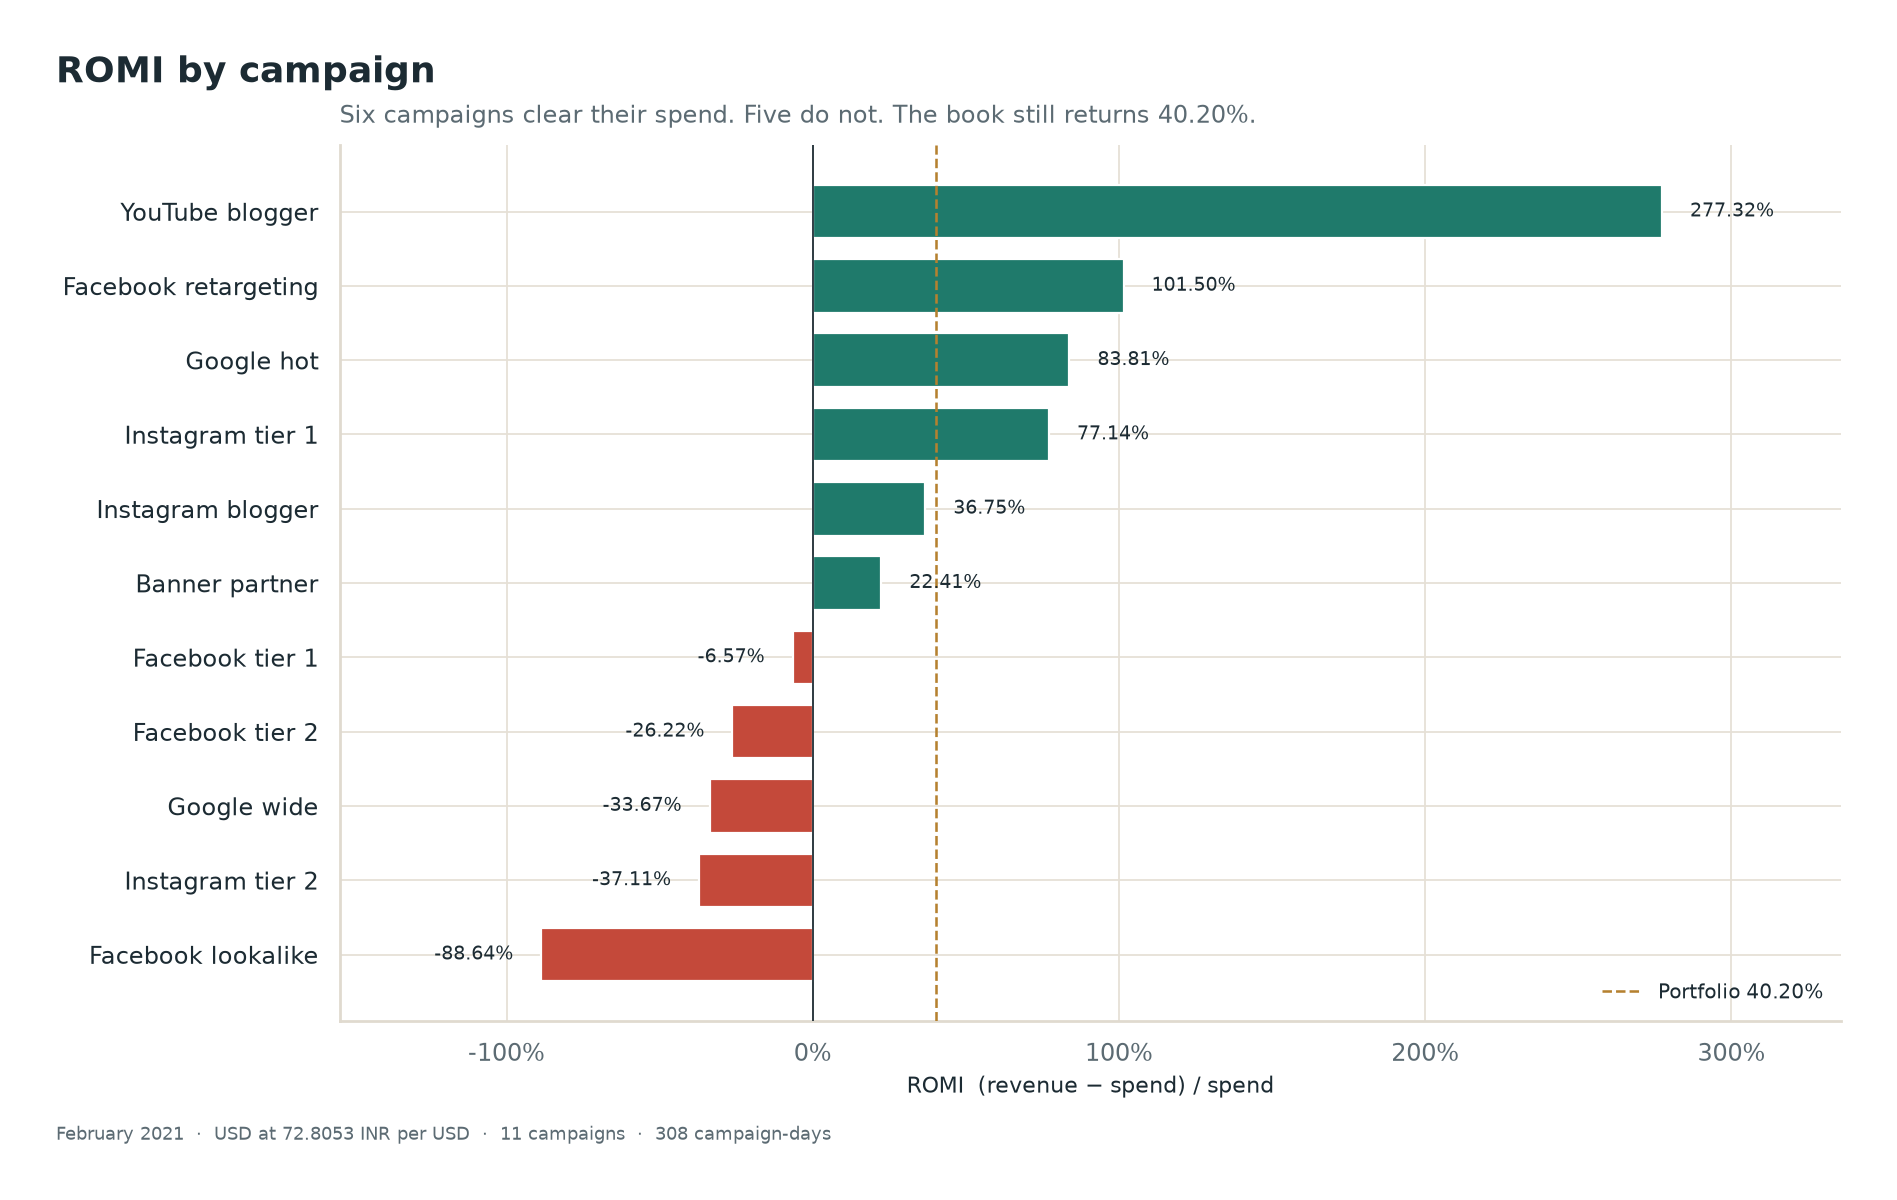

### funnel.png

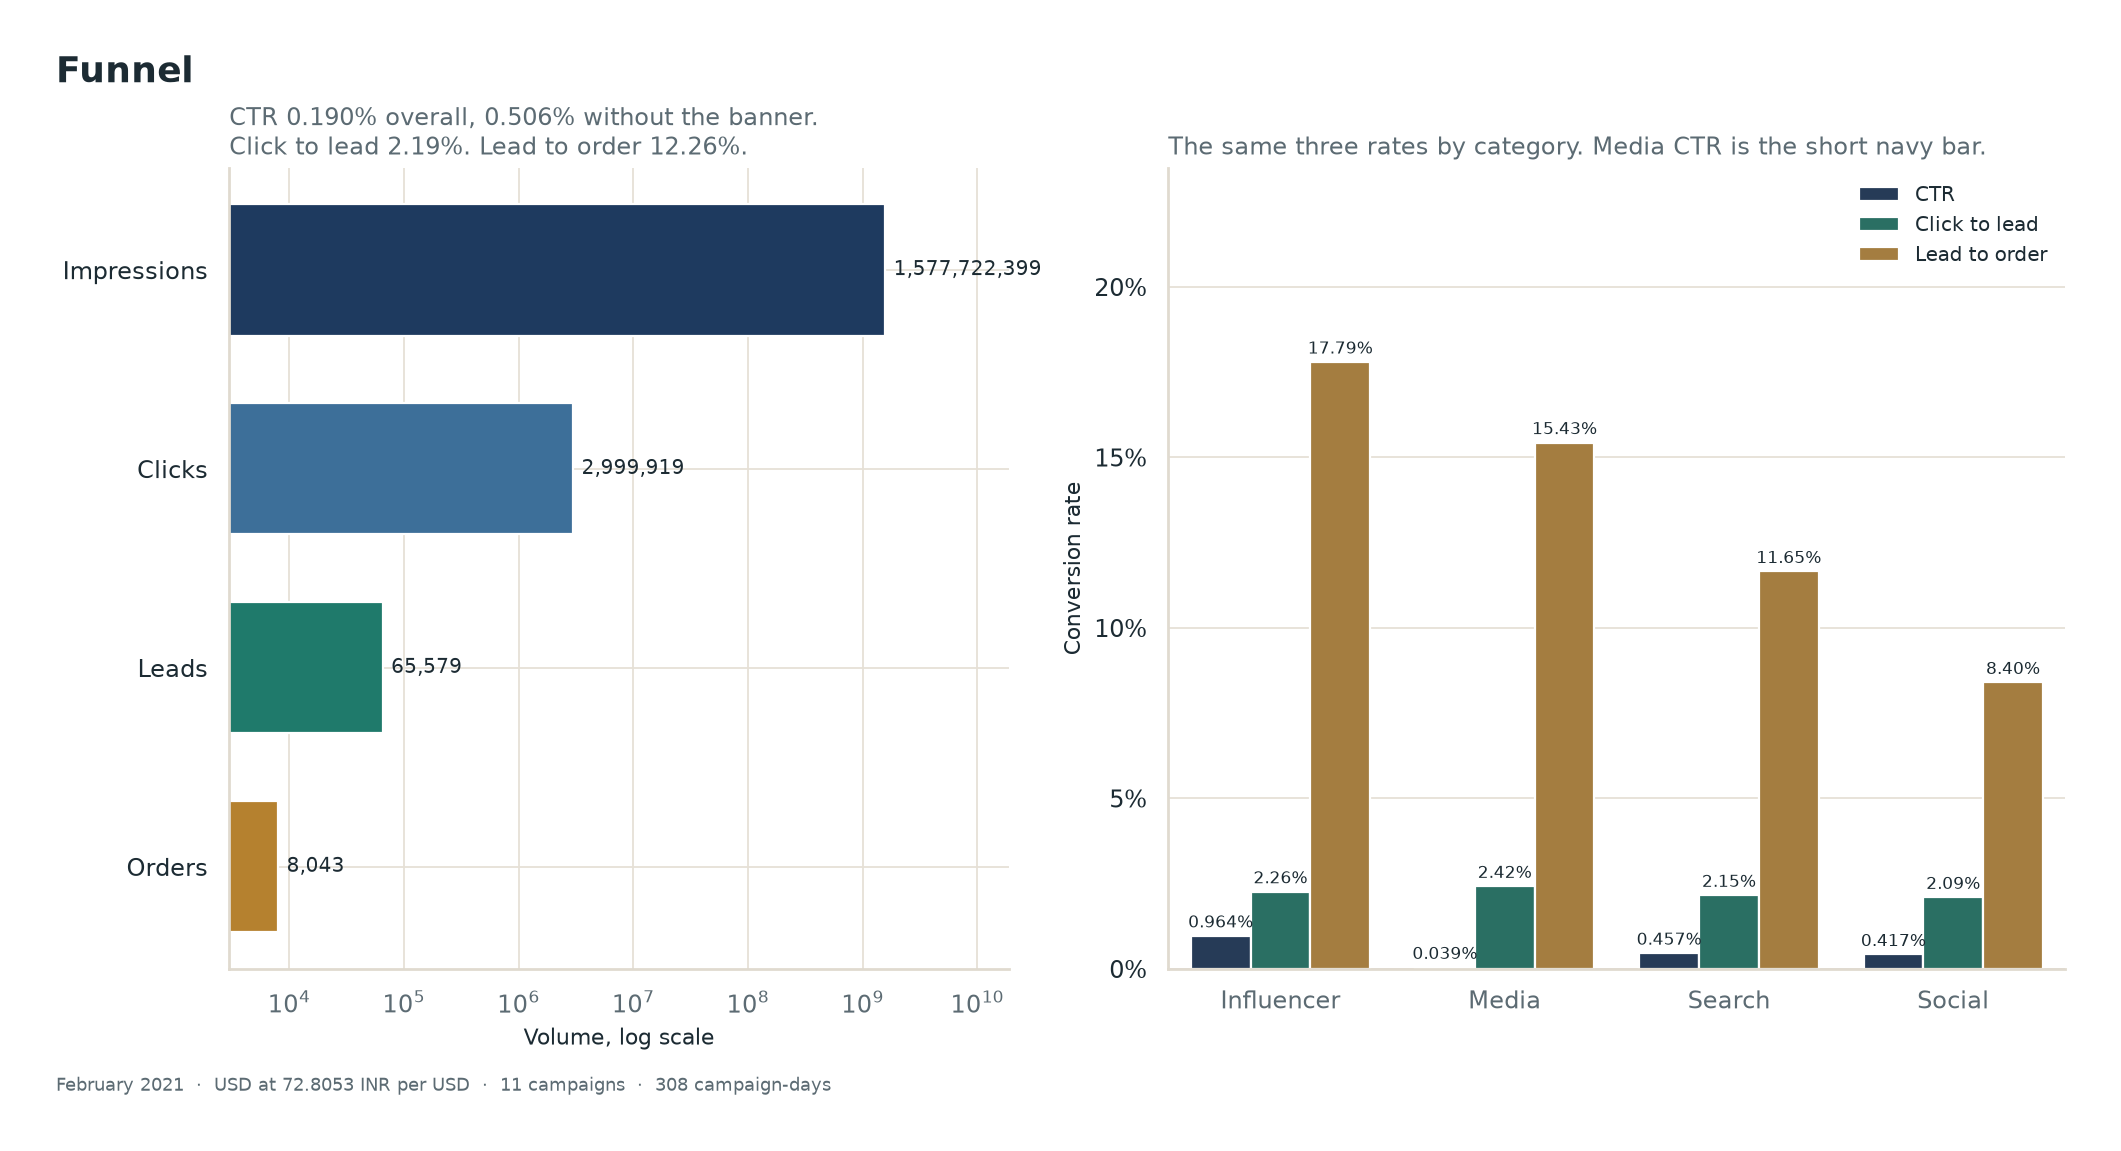

### spend_vs_revenue.png

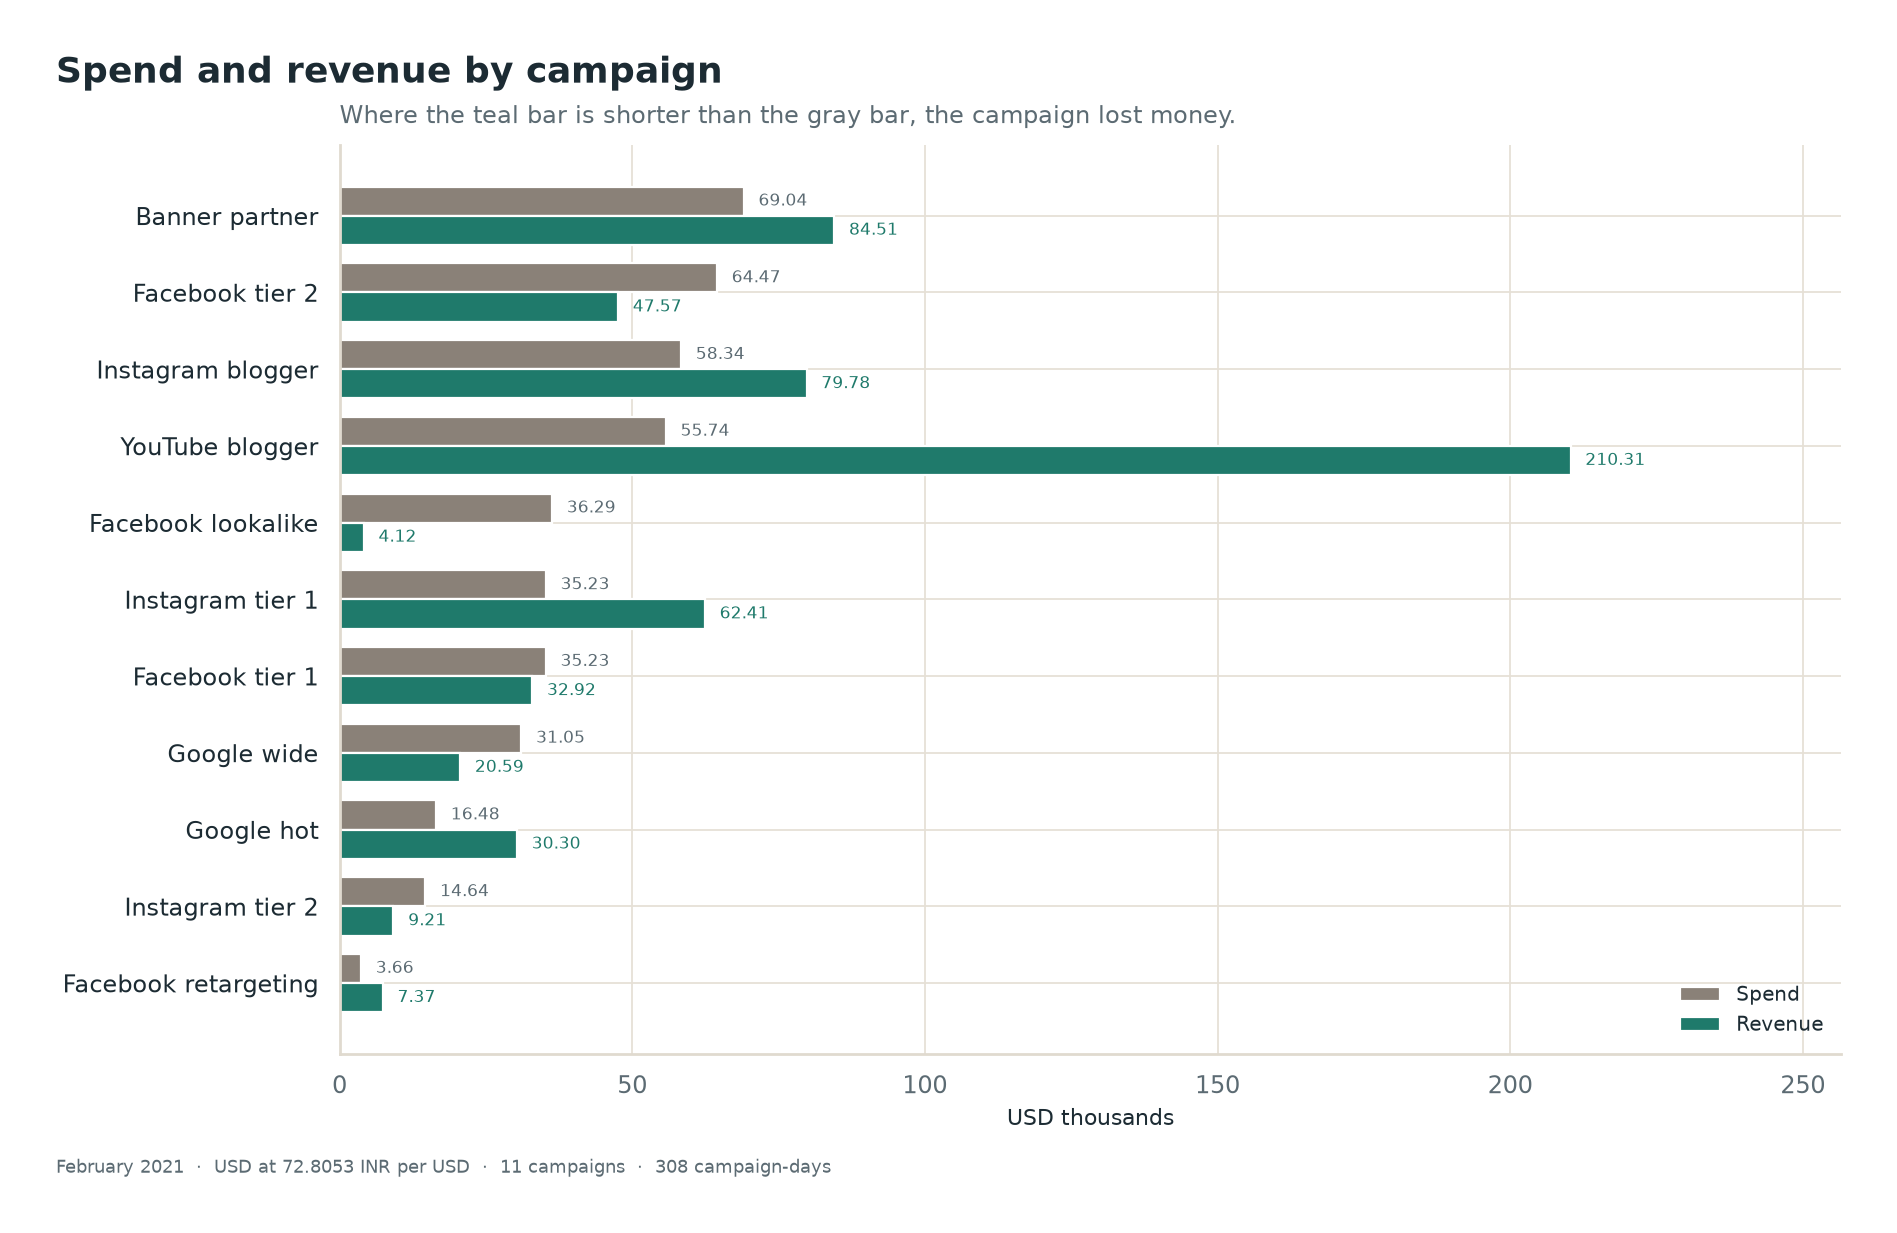

### tier_comparison.png

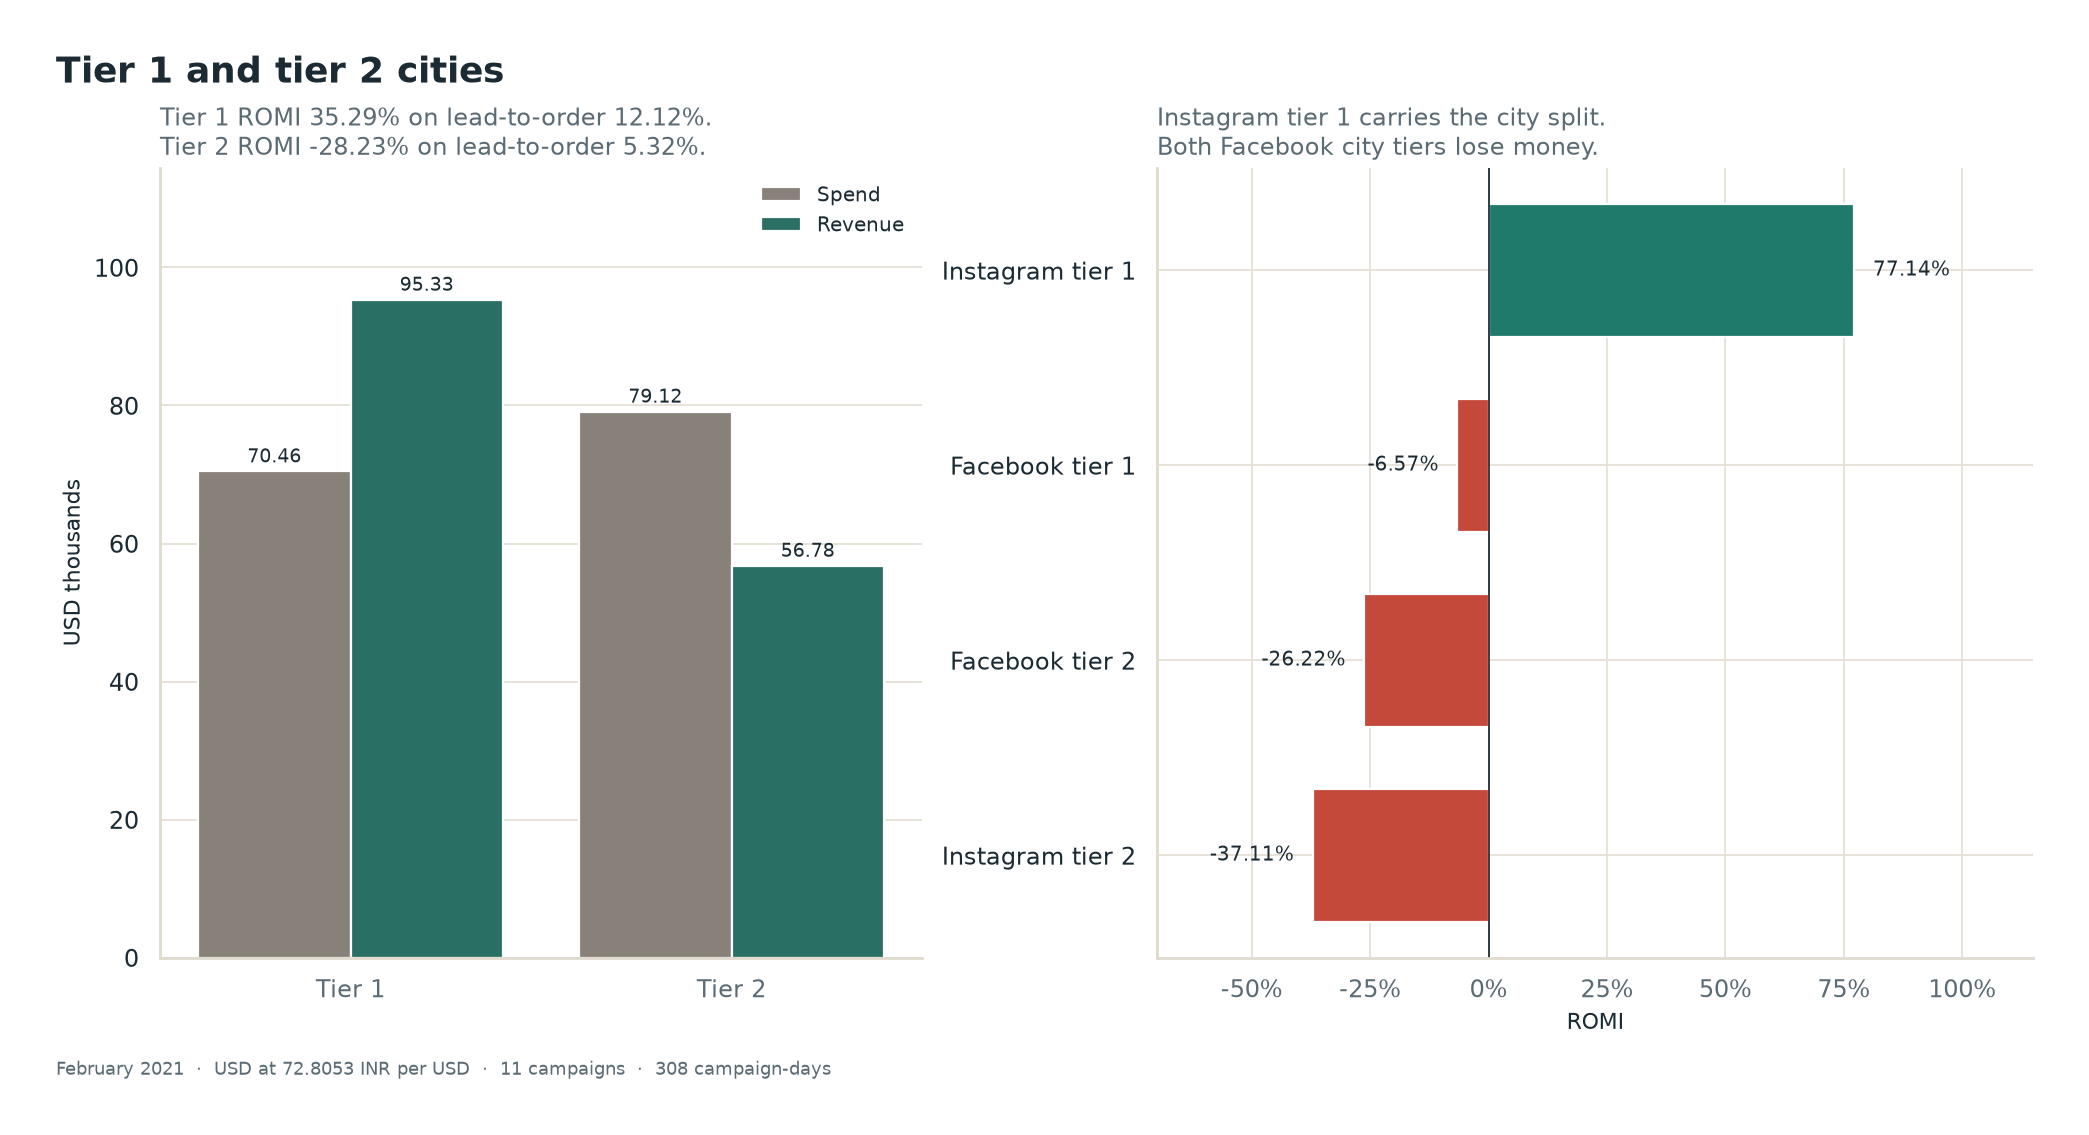

### targeting_comparison.png

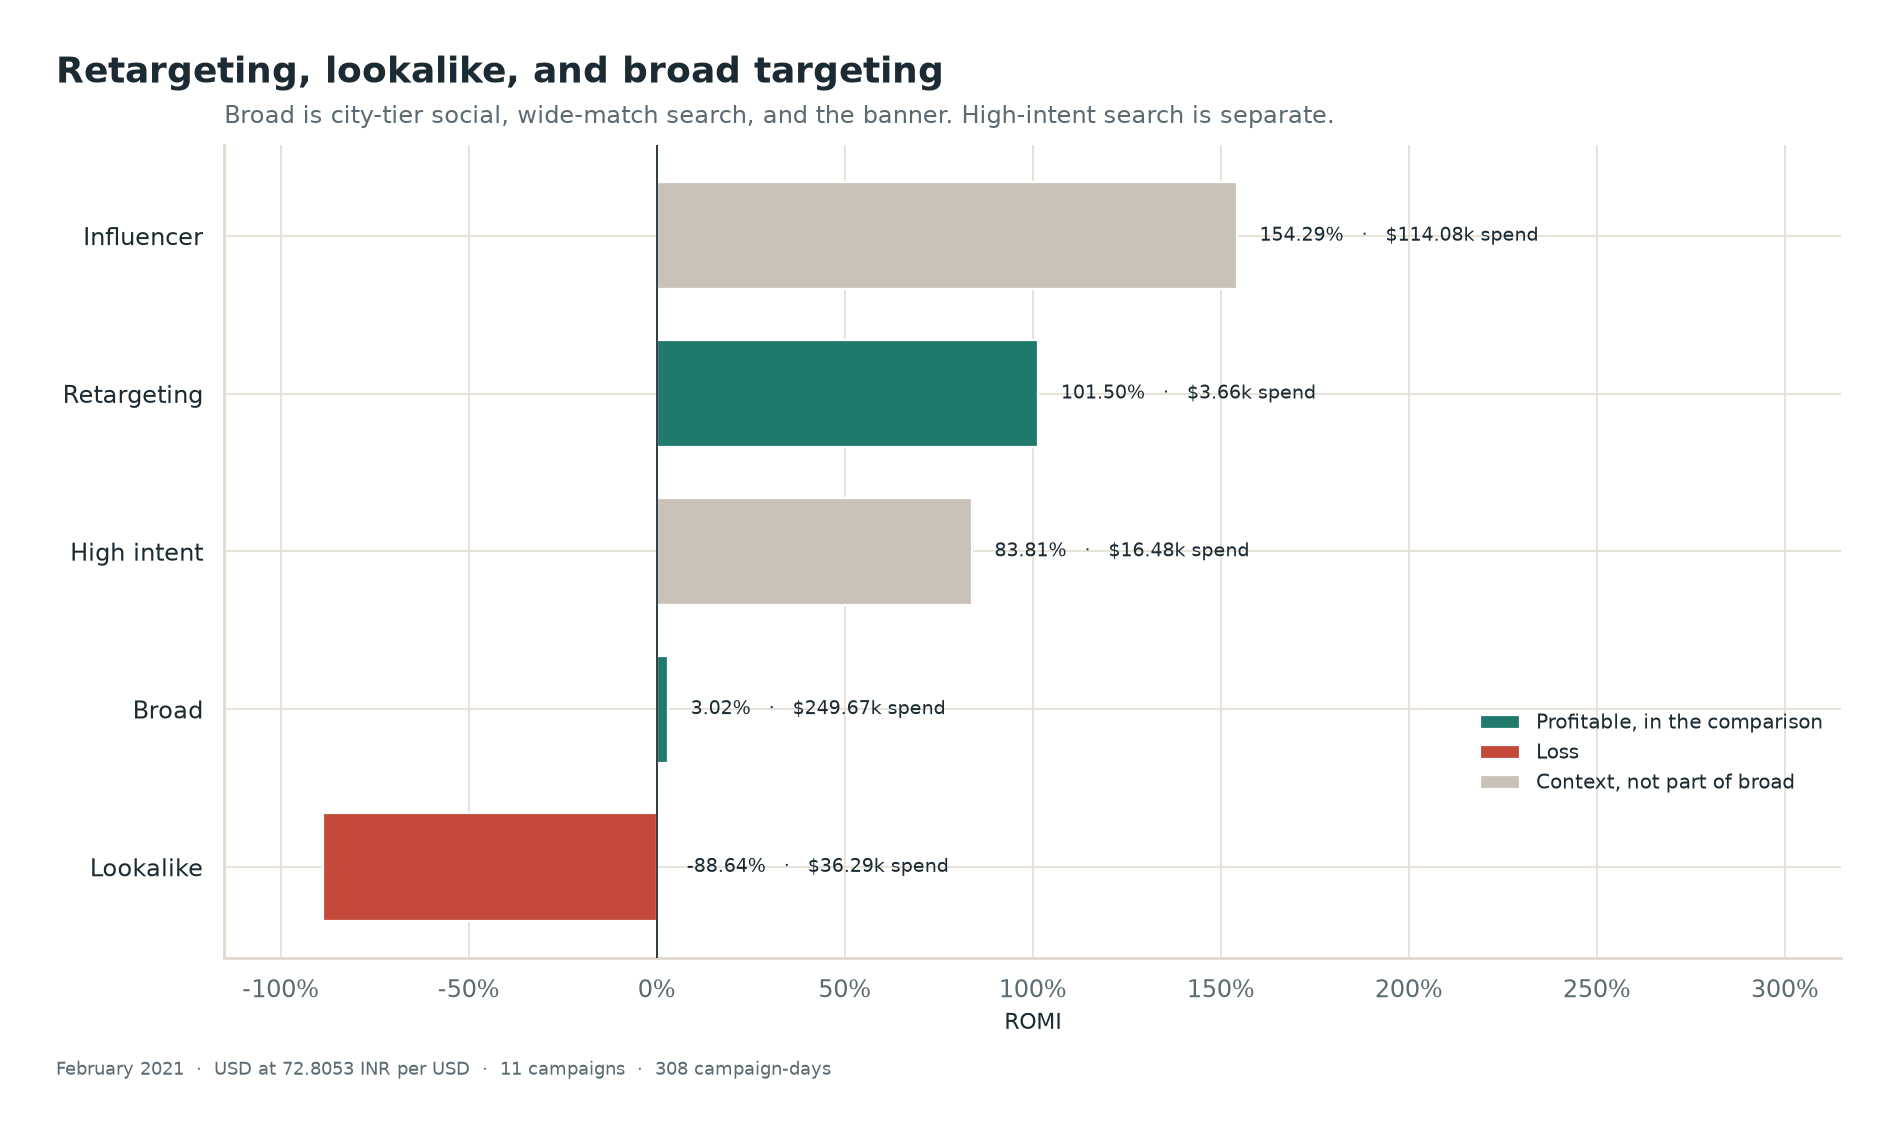

### daily_trend.png

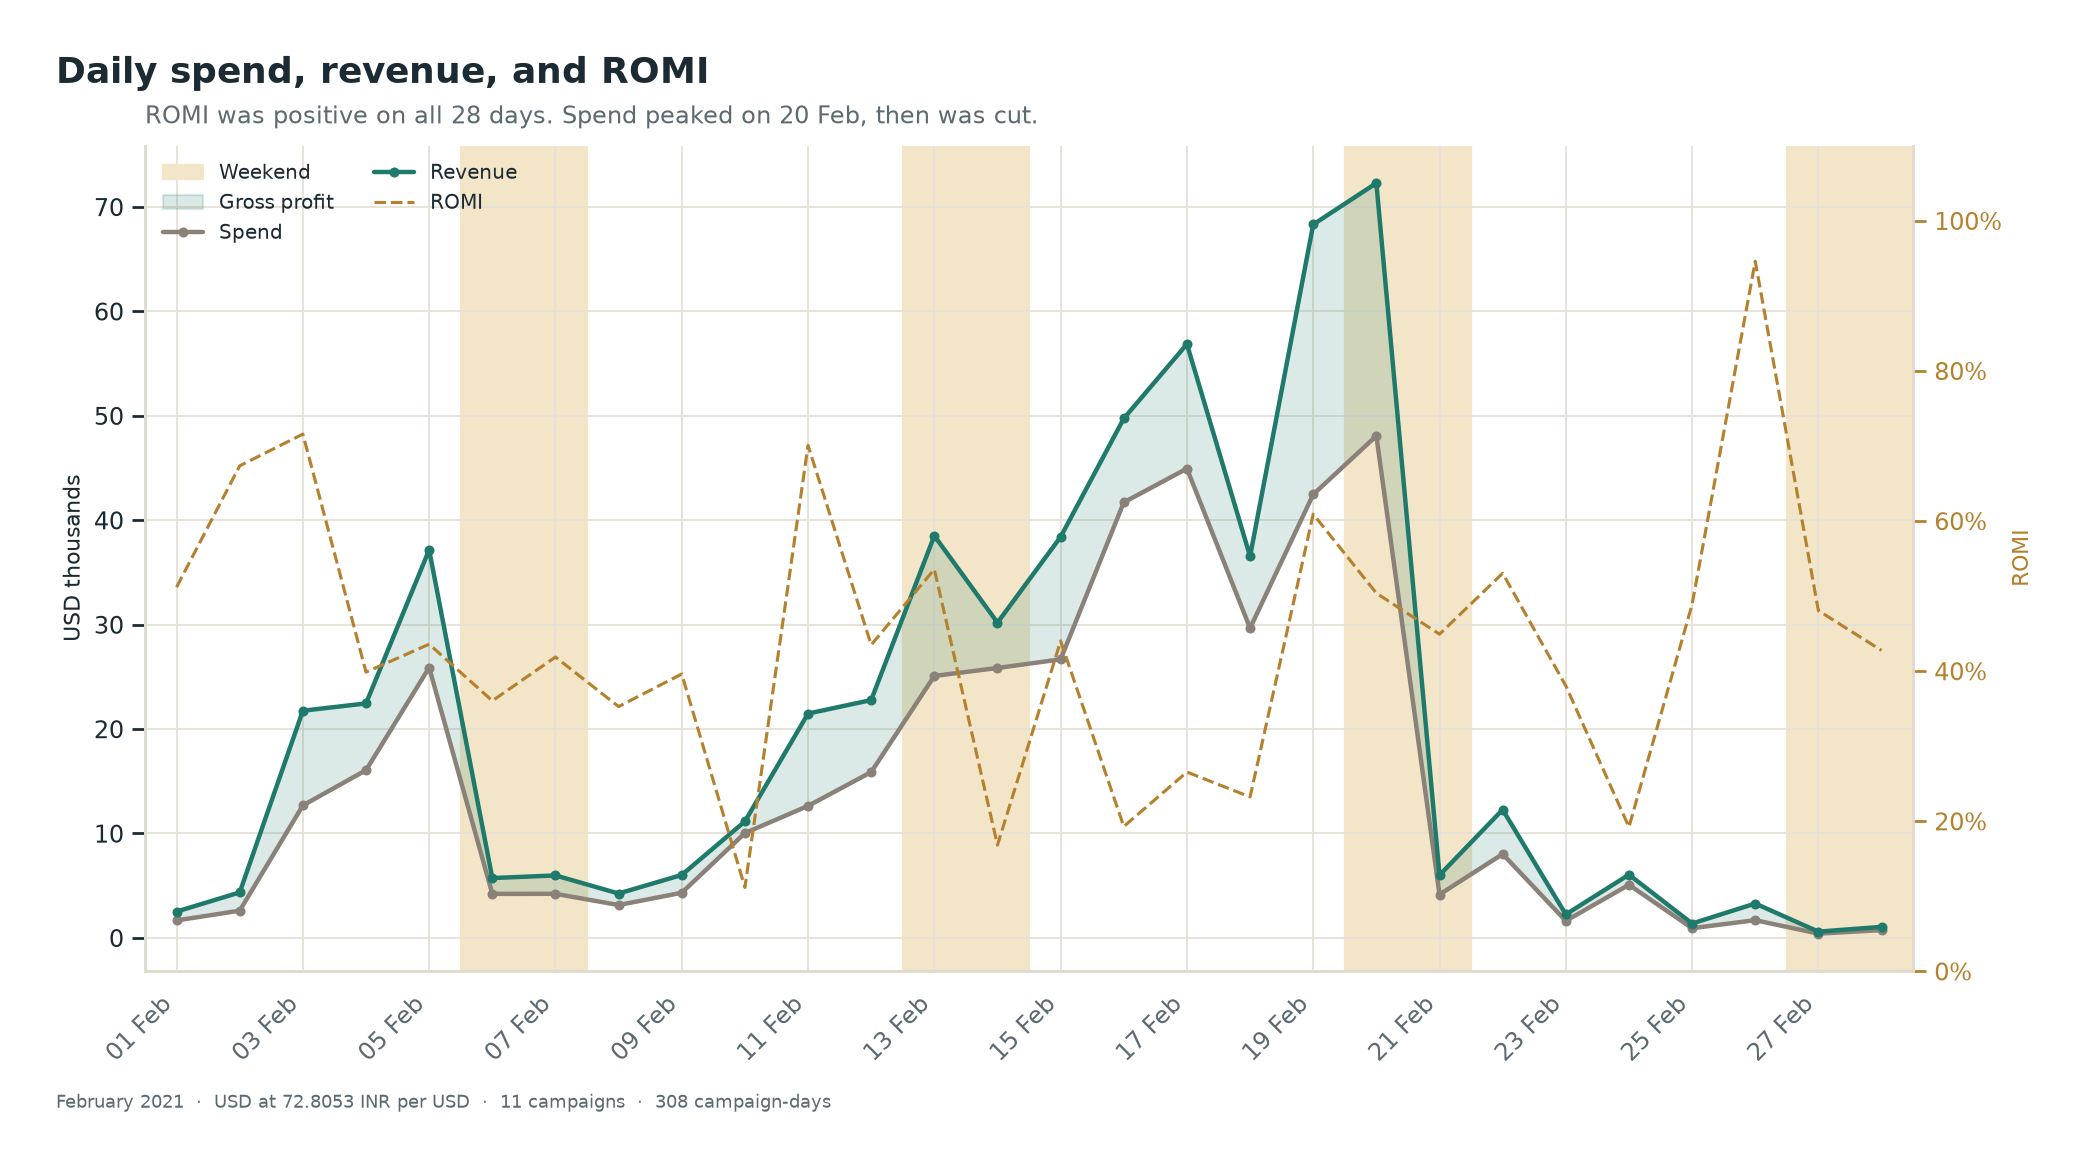

### weekday_vs_weekend.png

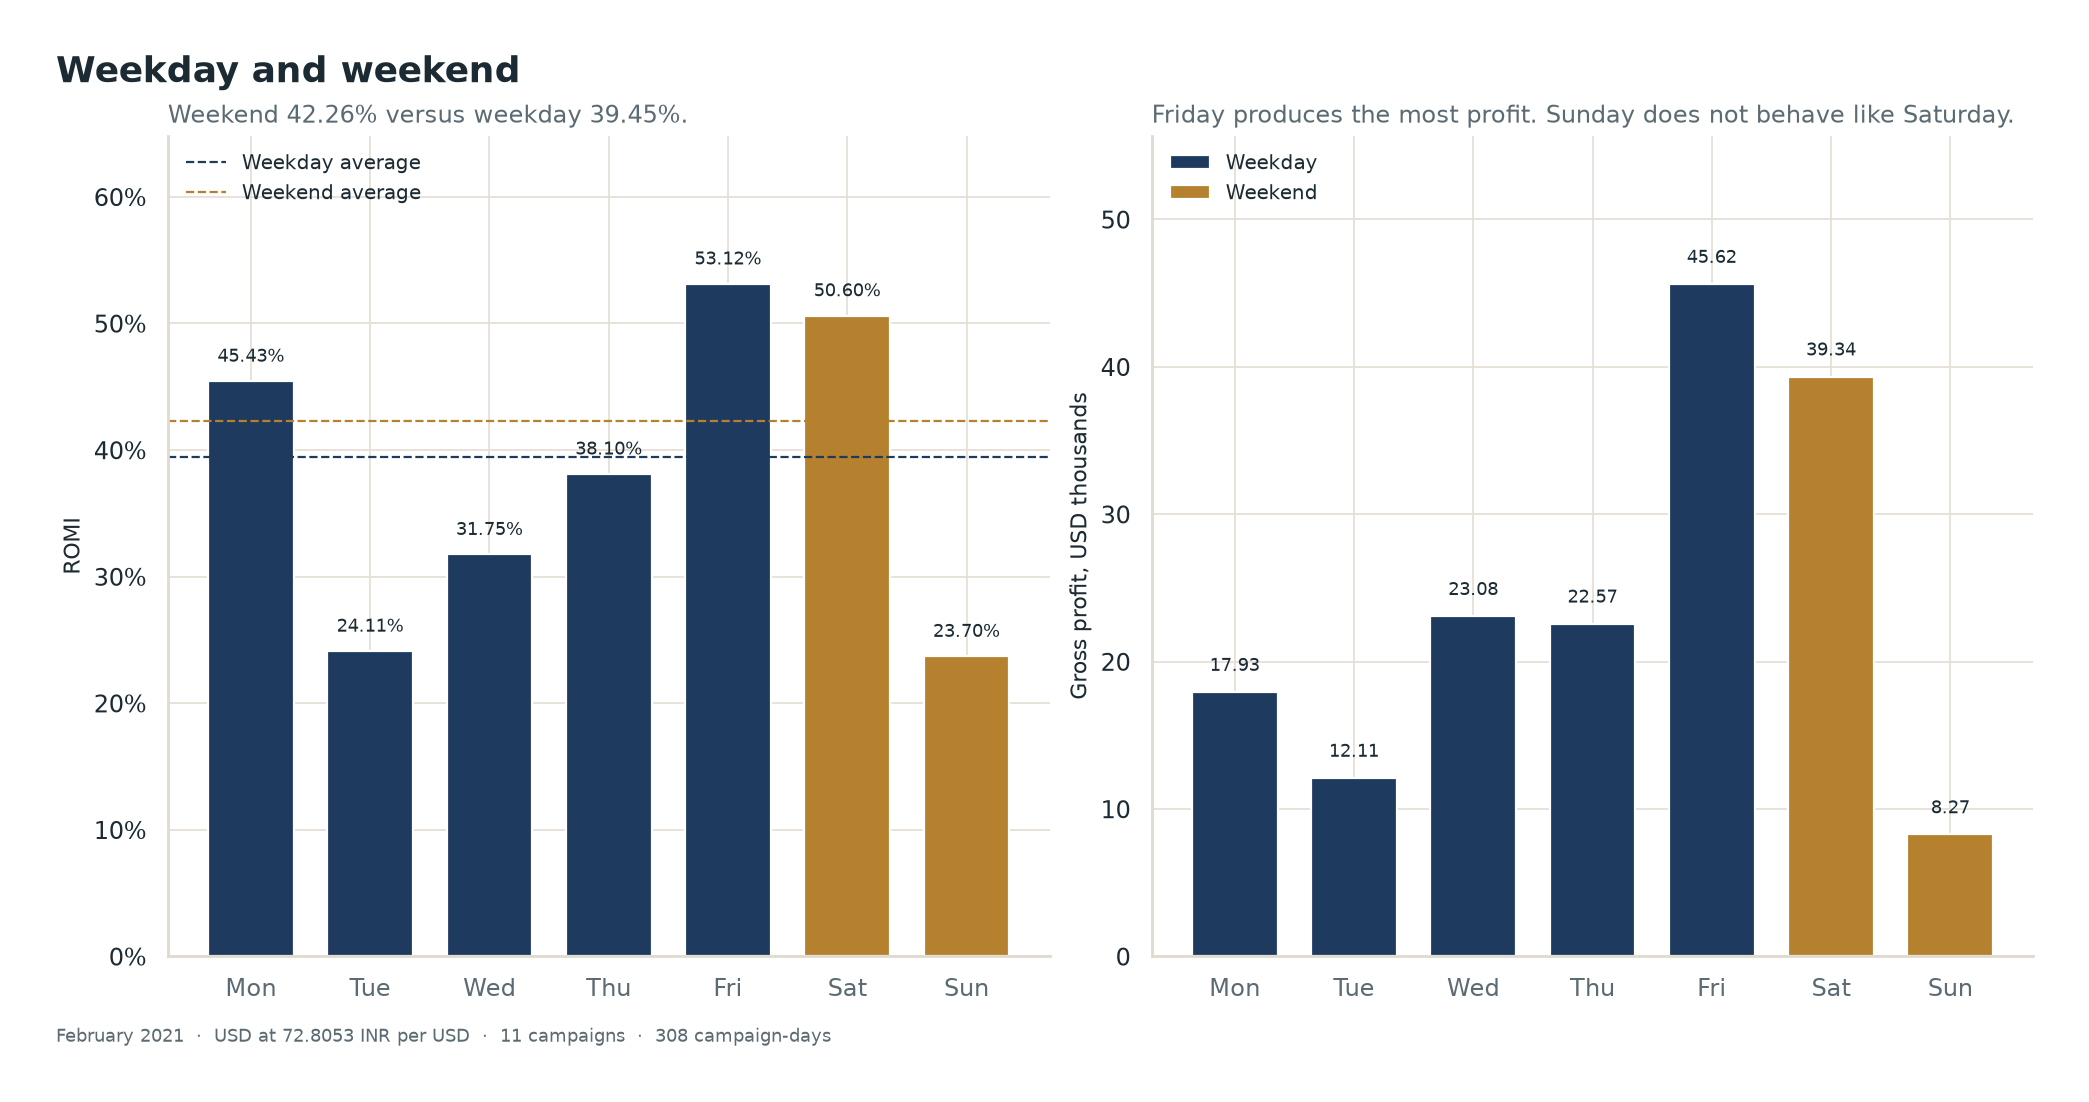

In [15]:
paths = render_all(report, ROOT / "images")
for path in paths:
    display(Markdown(f"### {path.name}"))
    display(Image(filename=str(path)))

## Checks

The published extract sums to a known number of rupee paise, and the converted book sums to a known number of cents. A mismatch means the raw file, the rate, or the cleaning step changed.


In [16]:
assert len(clean) == 308
assert clean["campaign_name"].nunique() == 11
from decimal import Decimal
assert INR_PER_USD == Decimal("72.8053")
assert int(overall.spend_cents) == 42_017_384
assert int(overall.revenue_cents) == 58_909_675
assert int(overall.gross_profit_cents) == 58_909_675 - 42_017_384
assert sorted(clean.loc[clean["campaign_name_raw"] != clean["campaign_name"], "campaign_name_raw"].unique()) == ["facebOOK_tier2"]
assert report["diagnostics"]["negative_romi_days"] == 0
print("Checks passed.")


Checks passed.


## Caveats

One month, observational. Gross profit ignores product cost. CAC is spend per order, not per new customer. Retargeting and lookalike exist only on Facebook, so the targeting comparison mixes platforms; the campaign table is the safer cut. The constant-ROMI reallocation is an upper bound, not a forecast. Banner impressions dominate CTR, so the blended 0.190% should be quoted next to the 0.506% excluding the banner.